In [2]:
import scipy as sp
#from scipy.misc import derivative
from scipy.special import jv, hankel2, hankel1, yv, jvp, yvp, factorial
from scipy.optimize import minimize
import numpy as np
import matplotlib.pyplot as plt
from numpy import sqrt, linspace, zeros, ones, pi, exp, conj, argmin, unravel_index, log, einsum, tan, log10, atan, cosh, heaviside
import torch
import warnings
warnings.filterwarnings("ignore")
from utils import h_z_cpa, h_z_cpa_denominator, h_z_cpa_numerator, e_z_cpa, e_z_cpa_numerator, hl2_prime, hl1_prime, hbar, c, alpha, graphene_conductivity
plt.rc('font', size=14)          # controls default text sizes

### In this notebook, we re-produce some of the figures of the following paper: [Self-consistent multimode lasing theory for complex or random lasing media](https://journals.aps.org/pra/pdf/10.1103/PhysRevA.74.043822?casa_token=hjAL2eDIFCMAAAAA%3A8Rq65VMyIWZsy_5yMTCO9tiBT2oXJnqNovmy7C0t-0IX18L9AVcAmKxCZ63-J6XEZQ9aBLaiS1nKxps). We first start with the constant flux states of a slab (with a perfectly reflecting mirror on one end). Note that the resonance positions may be trivially found by setting $\Psi(x<a)=\sin(n k_m x), \Psi(x>a)=\exp(ik_m (x-a))\sin(nk_m a)$, which gives us the following dispersion relation: $n\cos(nk_m a)=i\sin(n k_m a) \rightarrow \tan(nk_m a)=-i n$, which is **Equation 32** of the paper. 

In [98]:
def slab_resonance(m, n): # m indexes the mode number, n is the index of refraction
    return (pi/n)*(m+1/2)-(1j/(2*n))*log((n+1)/(n-1))

def constant_flux_slab(n, k, k_m): 
    return tan(n*k_m) + 1j*n*k_m/k

In [97]:
slab_qnm_frequency_paper = 11.51917306-0.53647930j
n = 1.5; m = 5
slab_qnm_frequency = slab_resonance(m, n)
percentage_diff_real = 100*(slab_qnm_frequency.real - slab_qnm_frequency_paper.real)/slab_qnm_frequency_paper.real
percentage_diff_imag = 100*(slab_qnm_frequency.imag - slab_qnm_frequency_paper.imag)/slab_qnm_frequency_paper.imag;
print(f"Percentage error in the real part of the frequency: {percentage_diff_real}")
print(f"Percentage error in the imaginary part of the frequency: {percentage_diff_imag}")

Percentage error in the real part of the frequency: 2.745487185622562e-08
Percentage error in the imaginary part of the frequency: 7.725740820998455e-07


In [182]:
N_real = 2000 # number of sampled points for the real part of the frequency
N_imag = 2000 # number of sampled points for the imaginary part of the frequency

k_m_real = linspace(11.554, 11.556, N_real); k_m_imag = linspace(-0.5311, -0.5309, N_imag)
k_m = k_m_real.reshape((N_real, 1)).repeat(N_imag, axis=1)+1j*k_m_imag.reshape((1, N_imag)).repeat(N_real, axis=0)
constant_flux_condition = constant_flux_slab(n, slab_qnm_frequency.real, k_m) # Fix k to real part of qnm frequency. Sweep k_m in the complex frequency plane.

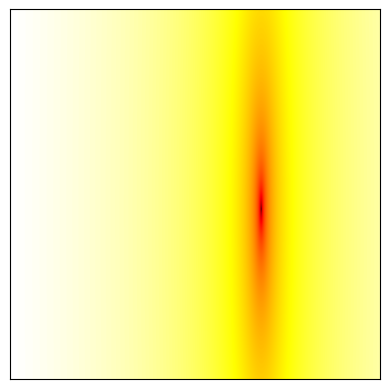

In [183]:
plt.imshow(log(np.abs(constant_flux_condition)**2).T, origin="lower", cmap="hot")
plt.xticks([])
plt.yticks([]);

In [187]:
constant_flux_idx = (np.abs(constant_flux_condition)**2).argmin();
constant_flux_frequency_paper = 11.55535804-0.53100809j
constant_flux_frequency = k_m.flatten()[constant_flux_idx]

percentage_diff_real = 100*(constant_flux_frequency.real - constant_flux_frequency_paper.real)/constant_flux_frequency_paper.real
percentage_diff_imag = 100*(constant_flux_frequency.imag - constant_flux_frequency_paper.imag)/constant_flux_frequency_paper.imag;
print(f"Percentage error in the real part of the frequency: {percentage_diff_real}")
print(f"Percentage error in the imaginary part of the frequency: {percentage_diff_imag}")

Percentage error in the real part of the frequency: -3.125481523834571e-06
Percentage error in the imaginary part of the frequency: -6.774470512964354e-06


### The function, `constant_flux` below evaluates the constant flux condition for a cylinder (**Equation 38** of the paper). 

In [2]:
def constant_flux(l, n, k, k_m): # angular momentum number, index of refraction, wavenumbers outside and inside the scatterer, respectively
    return n*k_m*jvp(l, n*k_m)*hankel1(l, k)-k*hl1_prime(l, k)*jv(l, n*k_m) 

### We first find the resonance frequency (which is complex valued). Note that the paper does not explicitly state the polarization but I believe it is assumed that the electric field is polarized along the cylinder's axis. 

In [3]:
qnm_frequency_paper = 71.17700357-0.74936509j; # Resonance frequency from Hakan's paper
l = 40 # angular momentum number
n = 1.3 # index of refraction of the cylinder
N_real = 250 # number of sampled points for the real part of the frequency
N_imag = 250 # number of sampled points for the imaginary part of the frequency
k_m_real = linspace(71.177002, 71.177005, N_real); k_m_imag = linspace(-0.749362, -0.749368, N_imag)
k_m = k_m_real.reshape((N_real, 1)).repeat(N_imag, axis=1)+1j*k_m_imag.reshape((1, N_imag)).repeat(N_real, axis=0)

In [4]:
qnm_condition = e_z_cpa(l, k_m, n**2);
qnm_idx = (np.abs(qnm_condition)**2).argmax();
qnm_frequency = k_m.flatten()[qnm_idx]

### Below, we compare our resonance frequency with that reported in the caption of Figure 3 of the paper. 

In [8]:
percentage_diff_real = 100*(qnm_frequency_paper.real-qnm_frequency.real)/qnm_frequency_paper.real
percentage_diff_imag = 100*(qnm_frequency_paper.imag-qnm_frequency.imag)/qnm_frequency_paper.imag
print(f"Percentage error in the real part of the frequency: {percentage_diff_real}")
print(f"Percentage error in the imaginary part of the frequency: {percentage_diff_imag}")

Percentage error in the real part of the frequency: -6.246095300037929e-08
Percentage error in the imaginary part of the frequency: -5.675487303052078e-06


### We create a heatmap to make sure there is a local maximum within the frequency ranges we sweeped.

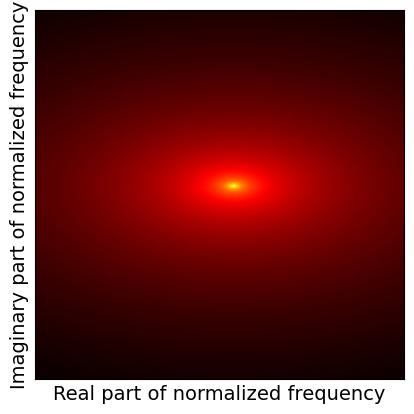

In [13]:
plt.imshow(np.log(np.abs(qnm_condition)**2).T, origin="lower", cmap="hot")
plt.xlabel("Real part of normalized frequency")
plt.ylabel("Imaginary part of normalized frequency")
plt.xticks([])
plt.yticks([]);

### We now find the constant flux state. We fix the external wavenumber to be that of the real part of the resonance's free space wavenumber. We then find the complex wavenumber that satisfies boundary conditions inside the scatterer. 

In [10]:
constant_flux_frequency_paper = 71.19539070-0.74853902j # Internal QNM frequency from Hakan's paper. 
N_real = 1000
N_imag = 1000 # number of sampled points for the imaginary part of the frequency
k_m_real = linspace(71.19538, 71.1954, N_real); k_m_imag = linspace(-0.74854, -0.748535, N_imag)
k_m = k_m_real.reshape((N_real, 1)).repeat(N_imag, axis=1)+1j*k_m_imag.reshape((1, N_imag)).repeat(N_real, axis=0)
constant_flux_condition = constant_flux(l, n, qnm_frequency.real, k_m) # Fix k to real part of qnm frequency. Sweep k_m in the complex frequency plane.
 
constant_flux_idx = (np.abs(constant_flux_condition)**2).argmin();
constant_flux_frequency = k_m.flatten()[constant_flux_idx]

### We create a heatmap to make sure there is a local minimum within the frequency ranges we sweeped.

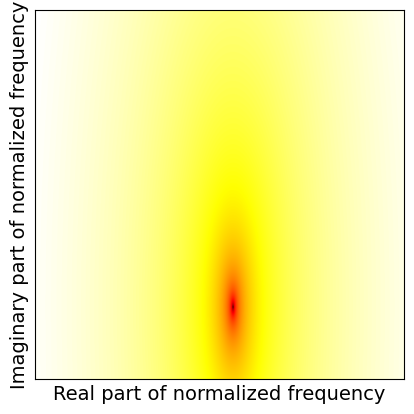

In [14]:
plt.imshow(np.log(np.abs(constant_flux_condition)**2).T, origin="lower", cmap="hot")
plt.xlabel("Real part of normalized frequency")
plt.ylabel("Imaginary part of normalized frequency")
plt.xticks([])
plt.yticks([]);

### Below, we compare our constant flux state frequency with that reported in the caption of Figure 3 of the paper. 

In [15]:
percentage_diff_real = 100*(constant_flux_frequency_paper.real-constant_flux_frequency.real)/constant_flux_frequency_paper.real
percentage_diff_imag = 100*(constant_flux_frequency_paper.imag-constant_flux_frequency.imag)/constant_flux_frequency_paper.imag
print(f"Percentage error in the real part of the frequency: {percentage_diff_real}")
print(f"Percentage error in the imaginary part of the frequency: {percentage_diff_imag}")

Percentage error in the real part of the frequency: -1.5044101707546405e-08
Percentage error in the imaginary part of the frequency: -1.2062202140019495e-06


In [16]:
qnm_frequency

np.complex128(71.17700361445783-0.7493651325301205j)

In [17]:
constant_flux_frequency

np.complex128(71.19539071071071-0.748539029029029j)

### We now plot the constant flux states as well as the resonances (for comparison, see Figure 3 of the paper) 

In [38]:
n_r_over_a = 1000
r_over_a_arr = linspace(1e-3, 2, n_r_over_a)

In [45]:
qnm_wavefunction_inside = jv(l, n*r_over_a_arr*qnm_frequency)
qnm_wavefunction_outside = hankel1(l, r_over_a_arr*qnm_frequency)*jv(l, n*qnm_frequency)/hankel1(l, qnm_frequency)
qnm_wavefunction = heaviside(1-r_over_a_arr, 0.5)*qnm_wavefunction_inside + heaviside(r_over_a_arr-1, 0.5)*qnm_wavefunction_outside

constant_flux_wavefunction_inside = jv(l, n*r_over_a_arr*constant_flux_frequency)
constant_flux_wavefunction_outside = hankel1(l, r_over_a_arr*qnm_frequency.real)*jv(l, n*constant_flux_frequency)/hankel1(l, qnm_frequency.real)
constant_flux_wavefunction = heaviside(1-r_over_a_arr, 0.5)*constant_flux_wavefunction_inside + heaviside(r_over_a_arr-1, 0.5)*constant_flux_wavefunction_outside

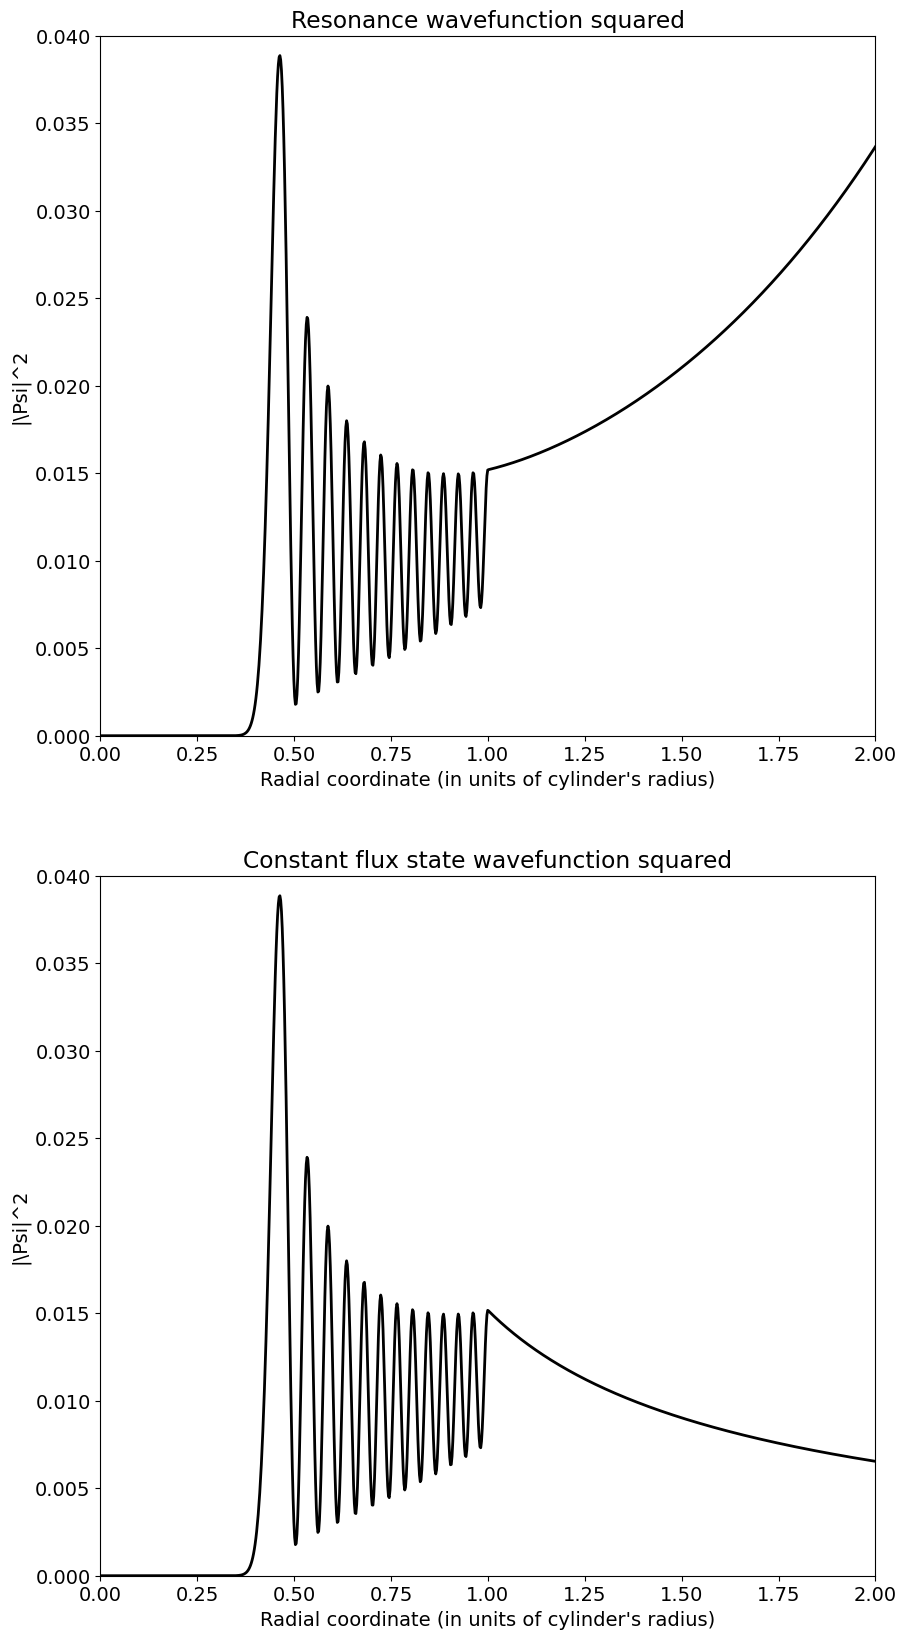

In [64]:
linewidth=2
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 20))
ax1.plot(r_over_a_arr, np.abs(qnm_wavefunction)**2, color="black", linewidth=linewidth)
ax1.set_xlim(0, 2)
ax1.set_ylim(0, 0.04)
ax1.set_title("Resonance wavefunction squared");
ax1.set_xlabel("Radial coordinate (in units of cylinder's radius)")
ax1.set_ylabel("|\Psi|^2")

ax2.plot(r_over_a_arr, np.abs(constant_flux_wavefunction)**2, color="black", linewidth=linewidth)
ax2.set_xlim(0, 2);
ax2.set_ylim(0, 0.04);
ax2.set_title("Constant flux state wavefunction squared");
ax2.set_xlabel("Radial coordinate (in units of cylinder's radius)");
ax2.set_ylabel("|\Psi|^2");